# Flock Surveillance Exploratory Analysis

This notebook pulls together the transparency-portal scrape outputs and the derived CSV summaries so we can start building plots and identifying the strongest story points for the paper.

The main themes below are:
- field coverage and how standardized the portals are
- what portals say they detect and prohibit
- retention and activity volume distributions
- the scale and geography of inter-agency data sharing

# Init

In [28]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import scipy.stats as ss
from matplotlib import mlab
import os, sys
import math
import json
from collections import defaultdict
from collections import OrderedDict
from collections import Counter
import seaborn as sns
import copy as copy
from matplotlib.patches import Arc
import matplotlib
font = {'family' : 'Times',
        'weight' : 'normal',
        'size'   : 12}
matplotlib.rc('font', **font)
import matplotlib.pyplot as plt
timesfont = {'fontname':'Times', 'fontsize':12}
import datetime
import time
from itertools import cycle, islice
from matplotlib import gridspec
import matplotlib.dates as mdates

In [29]:
from math import sqrt
SPINE_COLOR = 'gray'

def latexify(fig_width=None, fig_height=None, columns=1):
    """Set up matplotlib's RC params for LaTeX plotting.
    Call this before plotting a figure.
    Parameters
    ----------
    fig_width : float, optional, inches
    fig_height : float,  optional, inches
    columns : {1, 2}
    """

    # code adapted from http://www.scipy.org/Cookbook/Matplotlib/LaTeX_Examples

    # Width and max height in inches for IEEE journals taken from
    # computer.org/cms/Computer.org/Journal%20templates/transactions_art_guide.pdf

    assert(columns in [1,2])

    if fig_width is None:
        fig_width = 3.39 if columns==1 else 6.9 # width in inches

    if fig_height is None:
        golden_mean = (sqrt(5)-1.0)/2.0    # Aesthetic ratio
        fig_height = fig_width*golden_mean # height in inches

    MAX_HEIGHT_INCHES = 8.0
    if fig_height > MAX_HEIGHT_INCHES:
        print("WARNING: fig_height too large:" + fig_height +
              "so will reduce to" + MAX_HEIGHT_INCHES + "inches.")
        fig_height = MAX_HEIGHT_INCHES

    params = {'backend': 'ps',
              'text.latex.preamble': ['\\usepackage{gensymb}'],
              'axes.labelsize': 8, # fontsize for x and y labels (was 10)
              'axes.titlesize': 8,
              'font.size': 8, # was 10
              'legend.fontsize': 8, # was 10
              'xtick.labelsize': 8,
              'ytick.labelsize': 8,
              'text.usetex': True,
              'figure.figsize': [fig_width,fig_height],
              'font.family': 'times new roman'
    }

    #matplotlib.rcParams.update(params)
    return params


def format_axes(ax):

    for spine in ['top', 'right']:
        ax.spines[spine].set_color(SPINE_COLOR)
        ax.spines[spine].set_linewidth(0.5)

    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color(SPINE_COLOR)
        ax.spines[spine].set_linewidth(0.5)

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

    for axis in [ax.xaxis, ax.yaxis]:
        axis.set_tick_params(direction='in', color=SPINE_COLOR)

    return ax

latexify()

def getCDF(data):
    xdata = np.sort(data)
    ydata = [i/len(xdata) for i in range(len(xdata))]
    return xdata, ydata

def getCDFish(data):
    xdata = np.sort(data)
    ydata = [i for i in range(len(xdata))]
    return xdata, ydata

import re
def atoi(text):
    return int(text) if text.isdigit() else text

def natural_keys(text):
    '''
    alist.sort(key=natural_keys) sorts in human order
    http://nedbatchelder.com/blog/200712/human_sorting.html
    (See Toothy's implementation in the comments)
    '''
    return [ atoi(c) for c in re.split(r'(\d+)', text) ]

TIMESTAMP_STR_FORMATS = [
    '%Y%m%d_%H:%M:%S',
    '%Y-%m-%d %H:%M:%S.%f',
    '%Y%m%d %H:%M:%S',
    '%Y-%m-%d_%H:%M:%S',
    '%Y-%m-%dT%H:%M:%S.%f',
    '%H:%M:%S.%f',
    '%Y-%m-%dT%H:%M:%S.%f%z',
    '%Y%m%dT%H:%M:%S',
    '%Y-%m-%d_%H:%M:%S.%f',
    '%Y%m%d_%H:%M:%S.%f',
    '%Y-%m-%dT%H:%M:%S',
    '%Y-%m-%d %H:%M:%S',
]

# Load Data

In [30]:
from pathlib import Path
from IPython.display import display

analysis_dir = Path.cwd()
if not (analysis_dir / "flock_analysis_helpers.py").exists():
    analysis_dir = Path.cwd() / "analysis"
if str(analysis_dir) not in sys.path:
    sys.path.append(str(analysis_dir))

import importlib
import flock_analysis_helpers as fah

fah = importlib.reload(fah)
compute_story_metrics = fah.compute_story_metrics
load_portal_table = fah.load_portal_table
load_summary_tables = fah.load_summary_tables
summarize_granted_access_geography = fah.summarize_granted_access_geography

FONT_SIZE = 20
ONE_COL = (8, 5)
TWO_COL = (12, 7)

sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

tables = load_summary_tables()
portals = load_portal_table()
story = compute_story_metrics(portals)

field_counts = tables["field_counts"]
list_counts = tables["list_counts"]
numeric_summary = tables["numeric"]
orgs = tables["orgs"]
orgs_merged = tables["orgs_merged"]

portal_metrics = story["portal_metrics"]
share_geography = story.get("granted_access_geography")
if share_geography is None:
    share_geography = summarize_granted_access_geography(portals)
else:
    share_geography = share_geography.copy()
NUM_PORTALS = len(portals)
NUM_SHARED_PORTALS = len(share_geography)

In [31]:
def finalize_axes(ax):
    format_axes(ax)
    ax.tick_params(axis="both", labelsize=FONT_SIZE)
    return ax


def empirical_cdf(values):
    values = np.asarray(values)
    values = np.sort(values[~np.isnan(values)])
    if len(values) == 0:
        return values, values
    return values, np.arange(1, len(values) + 1) / len(values)


def slug_to_label(slug):
    parts = [part for part in str(slug).split("-") if part]
    pretty = []
    for part in parts:
        if len(part) <= 3:
            pretty.append(part.upper())
        else:
            pretty.append(part.replace("_", " ").title())
    return " ".join(pretty)


def add_horizontal_labels(ax, value_fmt="{:.1f}%", total=None):
    xmax = ax.get_xlim()[1]
    for patch in ax.patches:
        width = patch.get_width()
        y = patch.get_y() + patch.get_height() / 2
        if total is None:
            label = value_fmt.format(width)
        else:
            label = f"{int(round(width))} ({(width / total) * 100:.1f}%)"
        ax.text(width + xmax * 0.015, y, label, va="center", ha="left", fontsize=FONT_SIZE)


policy_label_map = {
    "usage based solely on a protected class": "Protected-class targeting",
    "harassment or intimidation": "Harassment or intimidation",
    "personal use": "Personal use",
    "immigration enforcement": "Immigration enforcement",
    "traffic enforcement": "Traffic enforcement",
}

coverage_label_map = {
    "Vehicles detected in the last 30 days": "Vehicles detected (30d)",
    "Searches in the last 30 days": "Searches (30d)",
    "Public Search Audit": "Public search audit",
    "Organizations granted access": "Organizations granted access",
    "Organizations sharing data": "Organizations sharing data",
}

share_category_order = [
    "In-state only",
    "Includes out-of-state only",
    "Includes federal only",
    "Includes federal and out-of-state",
]

In [32]:
inventory = pd.DataFrame(
    [
        {"dataset": "field_counts", "rows": field_counts.shape[0], "cols": field_counts.shape[1]},
        {"dataset": "list_counts", "rows": list_counts.shape[0], "cols": list_counts.shape[1]},
        {"dataset": "numeric_summary", "rows": numeric_summary.shape[0], "cols": numeric_summary.shape[1]},
        {"dataset": "orgs", "rows": orgs.shape[0], "cols": orgs.shape[1]},
        {"dataset": "orgs_merged", "rows": orgs_merged.shape[0], "cols": orgs_merged.shape[1]},
        {"dataset": "portal_table", "rows": portals.shape[0], "cols": portals.shape[1]},
    ]
)
inventory

,dataset,rows,cols
0,field_counts,60,2
1,list_counts,83,4
2,numeric_summary,11,2
3,orgs,541,2
4,orgs_merged,1,897
5,portal_table,897,339


In [33]:
quick_stats = pd.Series(
    {
        "portals_in_scrape": len(portals),
        "unique_normalized_fields": portals.shape[1],
        "median_filled_fields_per_portal": portal_metrics["filled_fields"].median(),
        "portals_with_org_sharing_list": portals["Organizations granted access"].notna().sum(),
        "portals_with_public_search_audit": portals["Public Search Audit"].notna().sum(),
        "portals_with_both_vehicle_and_unique_vehicle_counts": (
            portals["Vehicles detected in the last 30 days"].notna()
            & portals["Unique vehicles detected in the last 30 days"].notna()
        ).sum(),
    }
)
quick_stats

portals_in_scrape                                      897.0
unique_normalized_fields                               339.0
median_filled_fields_per_portal                         13.0
portals_with_org_sharing_list                          506.0
portals_with_public_search_audit                       309.0
portals_with_both_vehicle_and_unique_vehicle_counts      0.0
dtype: float64

## Portal Map

This map shows where the detected transparency portals are, aggregated by the state inferred from each portal slug.

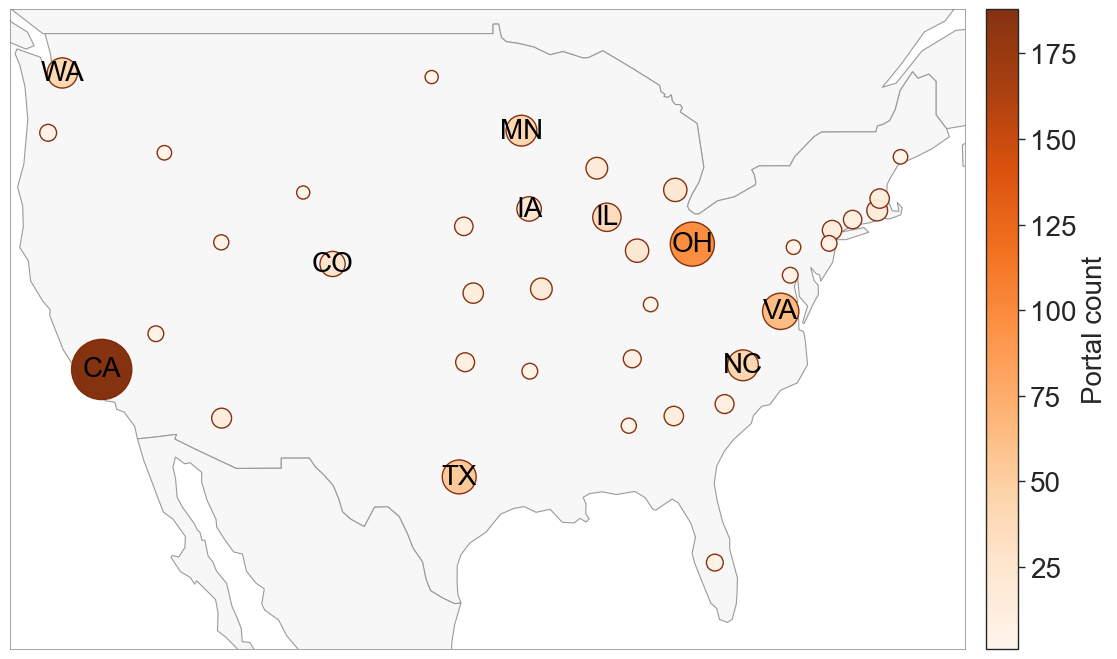

In [35]:
import geopandas as gpd
import pyogrio

state_map_df = story["state_counts"].rename_axis("state").reset_index(name="portal_count")
city_path = analysis_dir.parent / "data" / "cities" / "uscities.csv"
city_df = pd.read_csv(city_path, usecols=["state_id", "lat", "lng", "population"])
city_df["population"] = city_df["population"].fillna(1).clip(lower=1)

state_centroids = (
    city_df.groupby("state_id")
    .apply(
        lambda frame: pd.Series(
            {
                "lat": np.average(frame["lat"], weights=frame["population"]),
                "lng": np.average(frame["lng"], weights=frame["population"]),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)

map_df = state_map_df.merge(state_centroids, left_on="state", right_on="state_id", how="left")
map_df = map_df.dropna(subset=["lat", "lng"]).copy()
map_df = map_df[(map_df["lng"] >= -125) & (map_df["lng"] <= -66) & (map_df["lat"] >= 24) & (map_df["lat"] <= 50)]
map_df["size"] = 80 + (map_df["portal_count"] / map_df["portal_count"].max()) * 1800

world_path = Path(pyogrio.__file__).resolve().parent / "tests" / "fixtures" / "naturalearth_lowres" / "naturalearth_lowres.shp"
world = gpd.read_file(world_path)
north_america = world[world["name"].isin(["United States of America", "Canada", "Mexico"])].copy()

fig, ax = plt.subplots(figsize=TWO_COL)
north_america.plot(ax=ax, color="#f7f7f7", edgecolor="#9a9a9a", linewidth=0.8)

scatter = ax.scatter(
    map_df["lng"],
    map_df["lat"],
    s=map_df["size"],
    c=map_df["portal_count"],
    cmap="Oranges",
    edgecolors="#7f2704",
    linewidths=1.0,
    alpha=0.95,
    zorder=3,
)

for _, row in map_df.nlargest(10, "portal_count").iterrows():
    ax.text(row["lng"], row["lat"], row["state"], ha="center", va="center", fontsize=FONT_SIZE, color="black", zorder=4)

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])
finalize_axes(ax)
cbar = plt.colorbar(scatter, ax=ax, fraction=0.045, pad=0.02)
cbar.set_label("Portal count", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE)
plt.tight_layout()

## Field Coverage

This is better handled as a compact table than a bar chart in a space-constrained paper.

In [36]:
top_fields_table = (
    field_counts.sort_values("count", ascending=False)
    .head(16)
    .assign(percent_of_portals=lambda df: (df["count"] / NUM_PORTALS) * 100)
    .rename(columns={"field": "Field", "count": "Portal count", "percent_of_portals": "% of portals"})
)
top_fields_table["% of portals"] = top_fields_table["% of portals"].round(1)
display(top_fields_table.reset_index(drop=True))

,Field,Portal count,% of portals
0,What's Detected,858,95.7
1,Acceptable Use Policy,855,95.3
2,What's Not Detected,854,95.2
3,Prohibited Uses,854,95.2
4,Access Policy,843,94.0
5,Hotlist Policy,836,93.2
6,Data retention (in days),825,92.0
7,Hotlist hits in the last 30 days,798,89.0
8,Hotlists Alerted On,793,88.4
9,Number of LPR and other cameras,786,87.6


## What Flock Detects

The larger panel now focuses on the most common sub-1% categories, and the inset summarizes the dominant recurring categories on the original 0-100% scale. The table below keeps the full category list visible.


In [ ]:
import textwrap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

detected_plot = story["detected_items"].copy()
detected_plot["percent"] = detected_plot["rate"] * 100
detected_plot["rare"] = detected_plot["rate"] < 0.01
detected_plot["display_item"] = detected_plot["item"]
detected_common = detected_plot[~detected_plot["rare"]].copy()
detected_rare = detected_plot[detected_plot["rare"]].copy()
detected_rare_main = detected_rare.head(10).copy()
detected_rare_main["display_item"] = detected_rare_main["item"].map(lambda value: textwrap.fill(value, width=26))

fig, ax = plt.subplots(figsize=TWO_COL)
sns.barplot(data=detected_rare_main, y="display_item", x="percent", color="#a9d7df", ax=ax)
ax.set_xlabel("Rare-category share (% of portals)")
ax.set_ylabel("")
ax.set_xlim(0, max(0.5, detected_rare_main["percent"].max() * 1.55))
finalize_axes(ax)
add_horizontal_labels(ax, value_fmt="{:.2f}%")

if not detected_common.empty:
    inset_ax = inset_axes(ax, width="40%", height="42%", loc="lower right", borderpad=1.4)
    sns.barplot(data=detected_common, y="display_item", x="percent", color="#78b7c5", ax=inset_ax)
    inset_ax.set_xlabel("Common-category share (%)")
    inset_ax.set_ylabel("")
    inset_ax.set_xlim(0, 105)
    finalize_axes(inset_ax)
    add_horizontal_labels(inset_ax)
    inset_ax.set_facecolor("white")

plt.tight_layout()

detected_table = (
    detected_plot[["item", "count", "percent", "rare"]]
    .rename(
        columns={
            "item": "Detected item",
            "count": "Portal count",
            "percent": "% of portals with this field",
            "rare": "Rare (<1%)",
        }
    )
)
detected_table["% of portals with this field"] = detected_table["% of portals with this field"].round(2)
detected_table["Rare (<1%)"] = detected_table["Rare (<1%)"].map({True: "Yes", False: "No"})
display(detected_table.reset_index(drop=True))


## Prohibited Uses

The larger panel now focuses on the most common sub-1% prohibited-use categories, and the inset summarizes the dominant recurring policy language on the original 0-100% scale. The table below keeps the full category list visible.


In [ ]:
import textwrap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

prohibited_plot = story["prohibited_items"].copy()
prohibited_plot["display_item"] = prohibited_plot["item"].map(policy_label_map).fillna(prohibited_plot["item"].str.title())
prohibited_plot["percent"] = prohibited_plot["rate"] * 100
prohibited_plot["rare"] = prohibited_plot["rate"] < 0.01
prohibited_common = prohibited_plot[~prohibited_plot["rare"]].copy()
prohibited_rare = prohibited_plot[prohibited_plot["rare"]].copy()
prohibited_rare_main = prohibited_rare.head(12).copy()
prohibited_rare_main["display_item"] = prohibited_rare_main["display_item"].map(lambda value: textwrap.fill(value, width=24))

fig, ax = plt.subplots(figsize=TWO_COL)
sns.barplot(data=prohibited_rare_main, y="display_item", x="percent", color="#f0c2ad", ax=ax)
ax.set_xlabel("Rare prohibited-use share (% of portals)")
ax.set_ylabel("")
ax.set_xlim(0, max(2.0, prohibited_rare_main["percent"].max() * 1.4))
finalize_axes(ax)
add_horizontal_labels(ax, value_fmt="{:.2f}%")

if not prohibited_common.empty:
    inset_ax = inset_axes(ax, width="42%", height="48%", loc="lower right", borderpad=1.4)
    sns.barplot(data=prohibited_common, y="display_item", x="percent", color="#e39d7a", ax=inset_ax)
    inset_ax.set_xlabel("Common-category share (%)")
    inset_ax.set_ylabel("")
    inset_ax.set_xlim(0, 105)
    finalize_axes(inset_ax)
    add_horizontal_labels(inset_ax)
    inset_ax.set_facecolor("white")

plt.tight_layout()

prohibited_table = (
    prohibited_plot[["display_item", "count", "percent", "rare"]]
    .rename(
        columns={
            "display_item": "Prohibited use",
            "count": "Portal count",
            "percent": "% of portals with this field",
            "rare": "Rare (<1%)",
        }
    )
)
prohibited_table["% of portals with this field"] = prohibited_table["% of portals with this field"].round(2)
prohibited_table["Rare (<1%)"] = prohibited_table["Rare (<1%)"].map({True: "Yes", False: "No"})
display(prohibited_table.reset_index(drop=True))


## Data Retention

A CDF makes the 30-day clustering and the long tail of higher-retention portals much clearer than a bar chart.

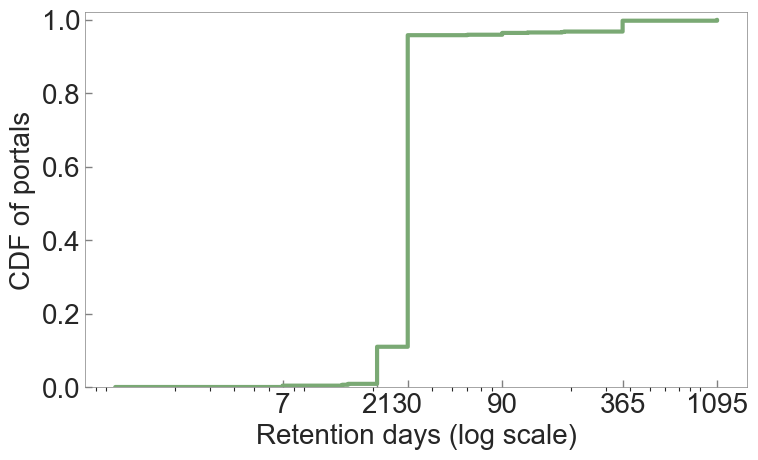

In [39]:
retention_values = portal_metrics["retention_days"].dropna()
x, y = empirical_cdf(retention_values.values)

fig, ax = plt.subplots(figsize=ONE_COL)
ax.plot(x, y, linewidth=3, color="#7aa974", drawstyle="steps-post")
ax.set_xscale("log")
ax.set_xlabel("Retention days (log scale)")
ax.set_ylabel("CDF of portals")
ax.set_ylim(0, 1.02)
ax.set_xticks([7, 21, 30, 90, 365, 1095])
ax.set_xticklabels(["7", "21", "30", "90", "365", "1095"])
finalize_axes(ax)
plt.tight_layout()

## Transparency Gaps

This separates field availability from retention, and labels the share of the full portal set represented by each field.

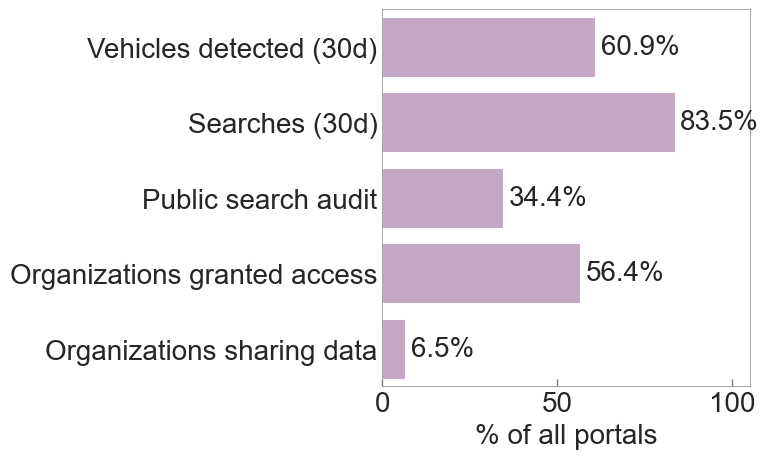

In [40]:
coverage_focus = (
    story["field_coverage"]
    .reindex([
        "Vehicles detected in the last 30 days",
        "Searches in the last 30 days",
        "Public Search Audit",
        "Organizations granted access",
        "Organizations sharing data",
    ])
    .rename_axis("field")
    .reset_index(name="count")
)
coverage_focus["display_field"] = coverage_focus["field"].map(coverage_label_map)
coverage_focus["percent"] = (coverage_focus["count"] / NUM_PORTALS) * 100

fig, ax = plt.subplots(figsize=ONE_COL)
sns.barplot(data=coverage_focus, y="display_field", x="percent", color="#c8a2c8", ax=ax)
ax.set_xlabel("% of all portals")
ax.set_ylabel("")
ax.set_xlim(0, 105)
finalize_axes(ax)
add_horizontal_labels(ax)
plt.tight_layout()

## Activity Volume Distributions

These are now plotted as CDFs. The x-axis is log-scaled because the distributions are very heavy-tailed.

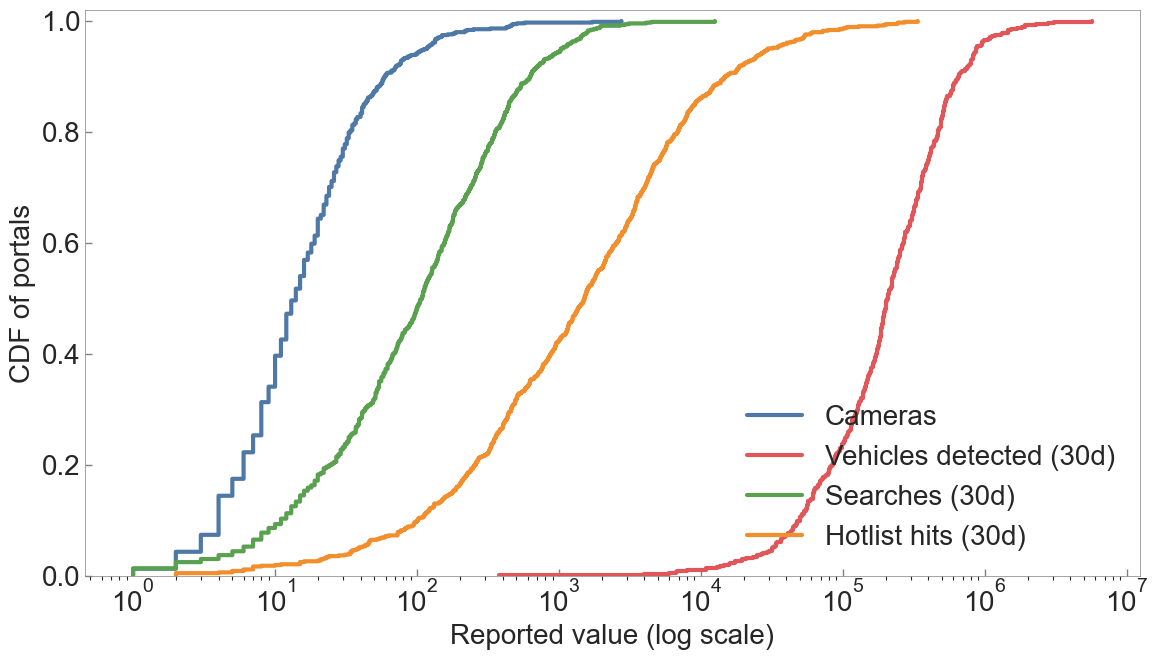

In [41]:
distribution_fields = [
    ("camera_count", "Cameras", "#4e79a7"),
    ("vehicles_30d", "Vehicles detected (30d)", "#e15759"),
    ("searches_30d", "Searches (30d)", "#59a14f"),
    ("hotlist_hits_30d", "Hotlist hits (30d)", "#f28e2b"),
]

fig, ax = plt.subplots(figsize=TWO_COL)

for column, label, color in distribution_fields:
    values = portal_metrics[column].dropna()
    values = values[values > 0]
    x, y = empirical_cdf(values.values)
    ax.plot(x, y, linewidth=3, label=label, color=color, drawstyle="steps-post")

ax.set_xscale("log")
ax.set_xlabel("Reported value (log scale)")
ax.set_ylabel("CDF of portals")
ax.set_ylim(0, 1.02)
finalize_axes(ax)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

## Cameras Versus Vehicle Detections

I kept the log-log scatter, added a fitted trend line, and now annotate both unusually high-detection portals and a few notably low-detection deployments.

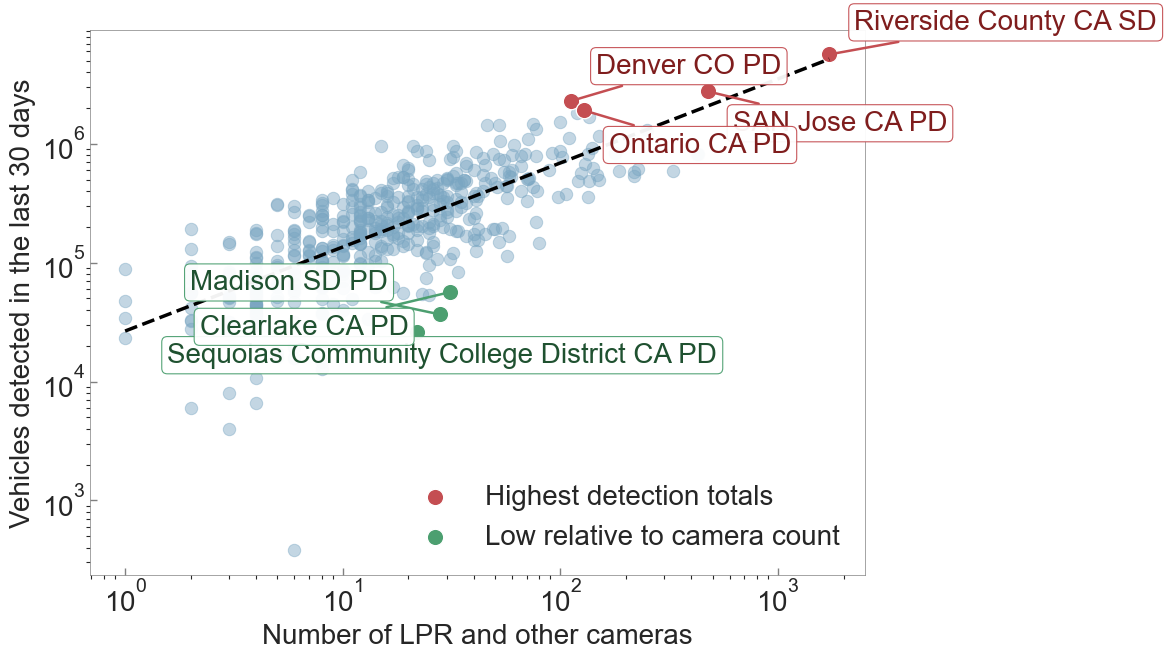

In [42]:
scatter = portal_metrics.dropna(subset=["camera_count", "vehicles_30d"]).copy()
scatter = scatter[(scatter["camera_count"] > 0) & (scatter["vehicles_30d"] > 0)]
scatter["log_x"] = np.log10(scatter["camera_count"])
scatter["log_y"] = np.log10(scatter["vehicles_30d"])
fit = np.polyfit(scatter["log_x"], scatter["log_y"], 1)
scatter["expected_log_y"] = fit[0] * scatter["log_x"] + fit[1]
scatter["residual"] = scatter["log_y"] - scatter["expected_log_y"]

high_points = scatter.nlargest(4, "vehicles_30d").copy()
low_points = scatter[scatter["camera_count"] > scatter["camera_count"].median()].nsmallest(3, "residual").copy()

fig, ax = plt.subplots(figsize=TWO_COL)
sns.scatterplot(data=scatter, x="camera_count", y="vehicles_30d", alpha=0.45, s=80, color="#7aa6c2", edgecolor=None, ax=ax)
sns.scatterplot(data=high_points, x="camera_count", y="vehicles_30d", s=140, color="#c44e52", ax=ax, label="Highest detection totals")
sns.scatterplot(data=low_points, x="camera_count", y="vehicles_30d", s=140, color="#4c9f70", ax=ax, label="Low relative to camera count")

x_line = np.linspace(scatter["camera_count"].min(), scatter["camera_count"].max(), 300)
y_line = 10 ** (fit[0] * np.log10(x_line) + fit[1])
ax.plot(x_line, y_line, linestyle="--", linewidth=2.5, color="black")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of LPR and other cameras")
ax.set_ylabel("Vehicles detected in the last 30 days")
finalize_axes(ax)
ax.legend(frameon=False, loc="lower right")

high_offsets = [(18, 18), (18, -28), (18, 20), (18, -30)]
for (slug, row), offset in zip(high_points.iterrows(), high_offsets):
    ax.annotate(
        slug_to_label(slug),
        xy=(row["camera_count"], row["vehicles_30d"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=FONT_SIZE,
        color="#7f1d1d",
        bbox={"facecolor": "white", "edgecolor": "#c44e52", "boxstyle": "round,pad=0.2", "alpha": 0.95},
        arrowprops={"arrowstyle": "-", "color": "#c44e52", "lw": 1.8},
    )

low_offsets = [(-180, -22), (-180, 18), (-180, -30)]
for (slug, row), offset in zip(low_points.iterrows(), low_offsets):
    ax.annotate(
        slug_to_label(slug),
        xy=(row["camera_count"], row["vehicles_30d"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=FONT_SIZE,
        color="#1f5130",
        bbox={"facecolor": "white", "edgecolor": "#4c9f70", "boxstyle": "round,pad=0.2", "alpha": 0.95},
        arrowprops={"arrowstyle": "-", "color": "#4c9f70", "lw": 1.8},
    )

plt.tight_layout()

## Sharing Network Scale

This shows how widely access spreads from a single portal once agencies publish a sharing list.

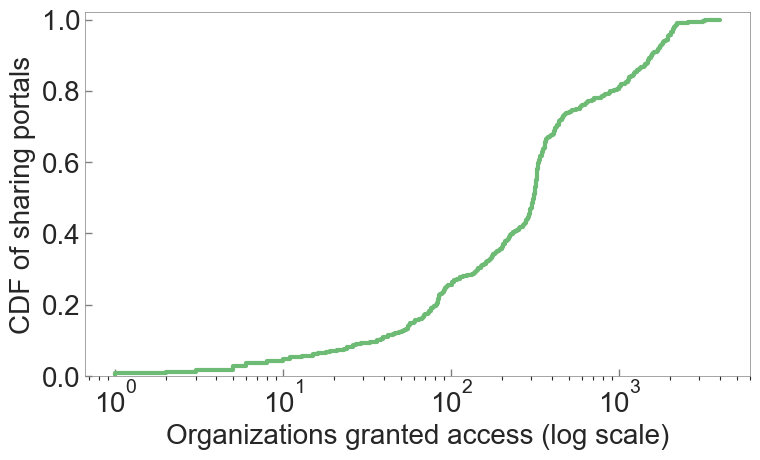

In [43]:
shared_partner_counts = portal_metrics["granted_access_partners"].dropna()
shared_partner_counts = shared_partner_counts[shared_partner_counts > 0]
x, y = empirical_cdf(shared_partner_counts.values)

fig, ax = plt.subplots(figsize=ONE_COL)
ax.plot(x, y, linewidth=3, color="#6dbb75", drawstyle="steps-post")
ax.set_xscale("log")
ax.set_xlabel("Organizations granted access (log scale)")
ax.set_ylabel("CDF of sharing portals")
ax.set_ylim(0, 1.02)
finalize_axes(ax)
plt.tight_layout()

## Sharing Geography

This classifies each portal with a sharing list into an exclusive category: only in-state sharing, out-of-state sharing, federal sharing, or both.

The geography classification is inferred from portal slugs and organization names, so ambiguous organizations may still need manual review later.

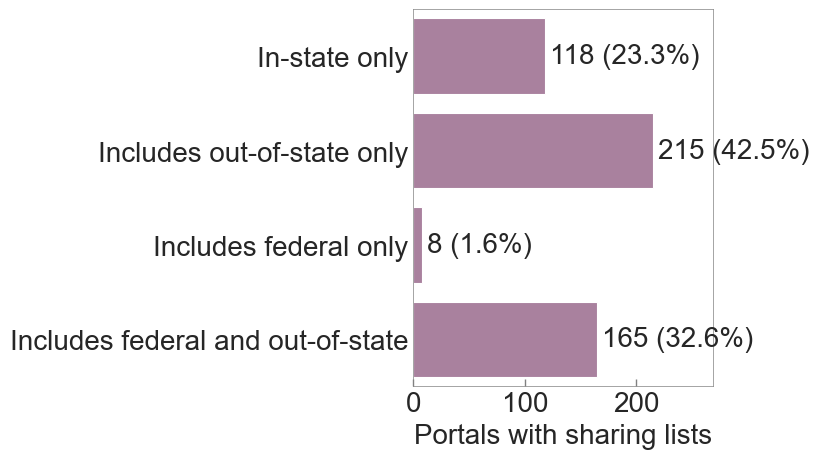

In [44]:
share_geo_plot = (
    share_geography["geography_category"]
    .value_counts()
    .reindex(share_category_order)
    .fillna(0)
    .rename_axis("category")
    .reset_index(name="count")
)

fig, ax = plt.subplots(figsize=ONE_COL)
sns.barplot(data=share_geo_plot, y="category", x="count", color="#b07aa1", ax=ax)
ax.set_xlabel("Portals with sharing lists")
ax.set_ylabel("")
ax.set_xlim(0, share_geo_plot["count"].max() * 1.25)
finalize_axes(ax)
add_horizontal_labels(ax, total=NUM_SHARED_PORTALS)
plt.tight_layout()

## Candidate Story Metrics

In [45]:
share_geo_counts = share_geo_plot.set_index("category")["count"]

candidate_story_metrics = pd.Series(
    {
        "portals_total": len(portals),
        "fields_total": portals.shape[1],
        "median_filled_fields": portal_metrics["filled_fields"].median(),
        "retention_exactly_30_days": (portal_metrics["retention_days"] == 30).sum(),
        "retention_at_least_365_days": (portal_metrics["retention_days"] >= 365).sum(),
        "median_granted_access_partners": shared_partner_counts.median(),
        "p90_granted_access_partners": shared_partner_counts.quantile(0.9),
        "in_state_only_sharing_portals": share_geo_counts.get("In-state only", 0),
        "out_of_state_only_sharing_portals": share_geo_counts.get("Includes out-of-state only", 0),
        "federal_only_sharing_portals": share_geo_counts.get("Includes federal only", 0),
        "federal_and_out_of_state_sharing_portals": share_geo_counts.get("Includes federal and out-of-state", 0),
        "median_searches_per_10k_vehicles": portal_metrics["searches_per_10k_vehicles"].median(),
        "median_hits_per_10k_vehicles": portal_metrics["hits_per_10k_vehicles"].median(),
        "top_state_in_portal_slug_counts": story["state_counts"].idxmax(),
        "top_state_portal_count": story["state_counts"].max(),
    }
)
candidate_story_metrics

portals_total                                     897
fields_total                                      339
median_filled_fields                             13.0
retention_exactly_30_days                         689
retention_at_least_365_days                        26
median_granted_access_partners                  309.5
p90_granted_access_partners                    1570.0
in_state_only_sharing_portals                     118
out_of_state_only_sharing_portals                 215
federal_only_sharing_portals                        8
federal_and_out_of_state_sharing_portals          165
median_searches_per_10k_vehicles             6.052497
median_hits_per_10k_vehicles                70.522068
top_state_in_portal_slug_counts                    CA
top_state_portal_count                            188
dtype: object